In [ ]:
!pip install tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import get_file
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
csv_path = get_file("airline-passengers.csv", origin=DATA_URL)

df = pd.read_csv(csv_path)

series = df.iloc[:, 1].values.astype("float32").reshape(-1, 1)

print("Dataset shape:", series.shape)
print(df.head())

Dataset shape: (144, 1)
     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121


In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(series)
plt.title("International Airline Passengers (1949-1960)")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.tight_layout()
plt.savefig("raw_series.png")
plt.close()

scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(series)

LOOK_BACK = 12

In [ ]:
def create_dataset(data, look_back=1):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back, 0]) #0 is to select vals in col 0
        y.append(data[i + look_back, 0])
    return np.array(X), np.array(y)

X, y = create_dataset(scaled, LOOK_BACK)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train = X_train.reshape((X_train.shape[0], LOOK_BACK, 1))
X_test = X_test.reshape((X_test.shape[0], LOOK_BACK, 1))

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (105, 12, 1) Test shape: (27, 12, 1)


In [ ]:
def train_and_evaluate(model, name, epochs=100):
    model.compile(optimizer="adam", loss="mse")
    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=epochs, batch_size=8, verbose=0
    )

    train_pred = model.predict(X_train, verbose=0)
    test_pred = model.predict(X_test, verbose=0)

    train_pred_inv = scaler.inverse_transform(train_pred)
    y_train_inv = scaler.inverse_transform(y_train.reshape(-1, 1))
    test_pred_inv = scaler.inverse_transform(test_pred)
    y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

    train_rmse = np.sqrt(mean_squared_error(y_train_inv, train_pred_inv))
    test_rmse = np.sqrt(mean_squared_error(y_test_inv, test_pred_inv))
    print(f"\n[{name}] Train RMSE: {train_rmse:.2f} | Test RMSE: {test_rmse:.2f}")

    plt.figure(figsize=(6, 4))
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="val loss")
    plt.title(f"{name} - Loss curve")
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{name.lower()}_loss.png")
    plt.close()

    return test_pred_inv, y_test_inv, test_rmse

In [ ]:
rnn_model = Sequential([
    SimpleRNN(50, activation="tanh", input_shape=(LOOK_BACK, 1)),
    Dense(1)
])
rnn_pred, y_test_inv, rnn_rmse = train_and_evaluate(rnn_model, "SimpleRNN")

lstm_model = Sequential([
    LSTM(50, activation="tanh", input_shape=(LOOK_BACK, 1)),
    Dense(1)
])
lstm_pred, _, lstm_rmse = train_and_evaluate(lstm_model, "LSTM")

gru_model = Sequential([
    GRU(50, activation="tanh", input_shape=(LOOK_BACK, 1)),
    Dense(1)
])
gru_pred, _, gru_rmse = train_and_evaluate(gru_model, "GRU")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



[SimpleRNN] Train RMSE: 12.95 | Test RMSE: 41.02


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



[LSTM] Train RMSE: 20.52 | Test RMSE: 49.50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



[GRU] Train RMSE: 21.02 | Test RMSE: 39.60


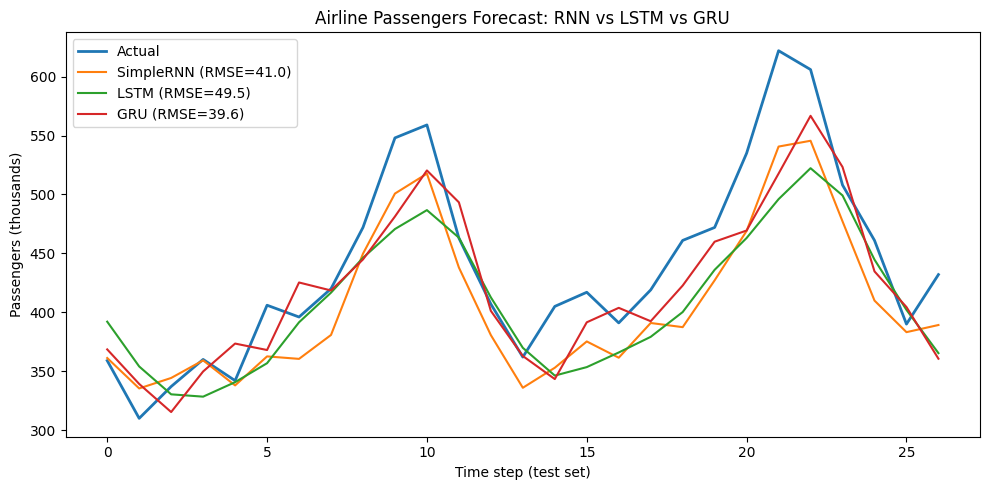

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(y_test_inv, label="Actual", linewidth=2)
plt.plot(rnn_pred, label=f"SimpleRNN (RMSE={rnn_rmse:.1f})")
plt.plot(lstm_pred, label=f"LSTM (RMSE={lstm_rmse:.1f})")
plt.plot(gru_pred, label=f"GRU (RMSE={gru_rmse:.1f})")
plt.title("Airline Passengers Forecast: RNN vs LSTM vs GRU")
plt.xlabel("Time step (test set)")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.tight_layout()
plt.savefig("rnn_vs_lstm_forecast.png")
plt.show()
plt.close()

raw_series.png


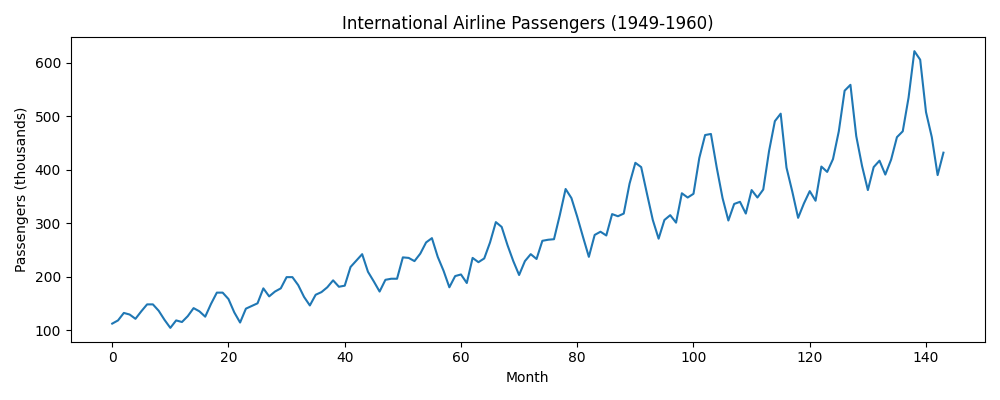

simplernn_loss.png


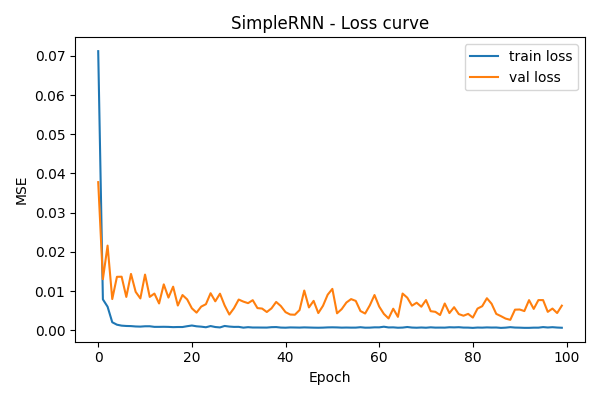

lstm_loss.png


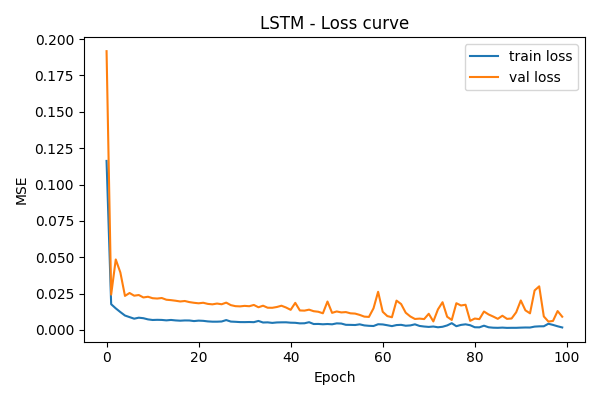

gru_loss.png


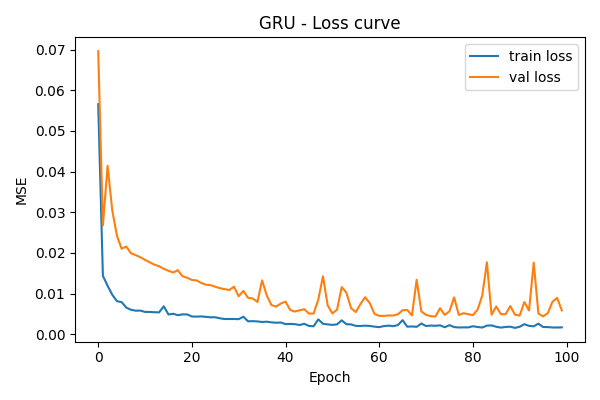

rnn_vs_lstm_forecast.png


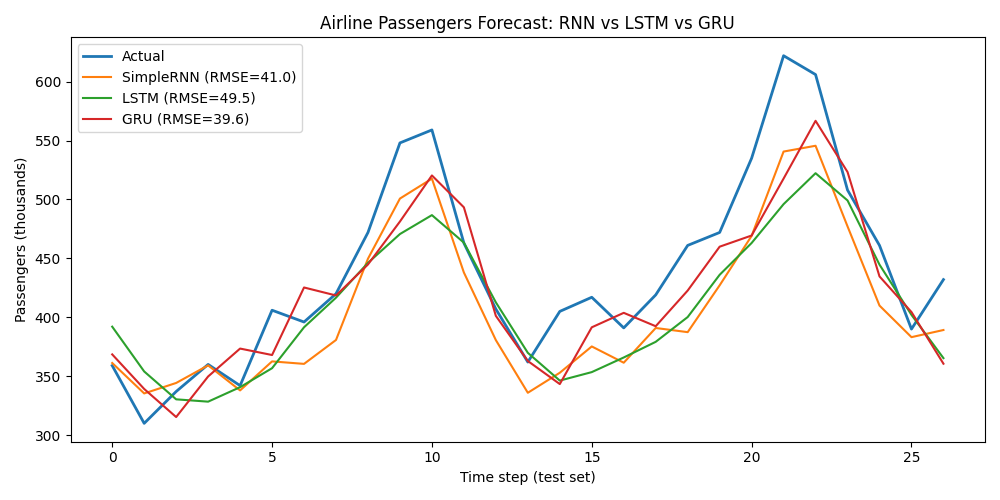

In [ ]:
from IPython.display import display, Image

files = [
    "raw_series.png",
    "simplernn_loss.png",
    "lstm_loss.png",
    "gru_loss.png",
    "rnn_vs_lstm_forecast.png"
]

for file in files:
    print(file)
    display(Image(filename=file))

In [ ]:
print("\nSaved plots: raw_series.png, simplernn_loss.png, lstm_loss.png, "
      "gru_loss.png, rnn_vs_lstm_forecast.png")
print(f"\nSummary -> SimpleRNN: {rnn_rmse:.2f} | LSTM: {lstm_rmse:.2f} | GRU: {gru_rmse:.2f}")


Saved plots: raw_series.png, simplernn_loss.png, lstm_loss.png, gru_loss.png, rnn_vs_lstm_forecast.png

Summary -> SimpleRNN: 41.02 | LSTM: 49.50 | GRU: 39.60
